# Modelos com Features LLM — Tabela de Ablação

**Estratégia de ablação:**
- M3: XGB apenas com features estruturadas de admissão (anti-leakage)
- M4: M3 + features obstétricas enriquecidas (regex + LLM overlay)
- M5: M4 + scores LLM diretos (severity, red_flag, flags clínicos)

**Desafio de cobertura:** llm_features cobre ~17k de 78k atendimentos (INNER JOIN).
Solução: LEFT JOIN com imputed=0 para ausentes (M5_full) + INNER JOIN como
análise de sensibilidade (M5_inner). DeLong + NRI/IDI quantificam o ganho.

In [1]:
from __future__ import annotations
import warnings, json
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
from scipy import stats as scipy_stats

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.4f}".format)

# ── Idioma / Language ─────────────────────────────────────────────────────────
LANG = "pt"  # "pt" | "en"  ← única linha a alterar para mudar idioma

_T = {
    "pt": {
        "cob_xlabel":          "Ano",
        "cob_ylabel":          "% com LLM",
        "cob_title":           "Cobertura LLM por Ano",
        "cob_retorno_ylabel":  "Taxa retorno 30d (%)",
        "cob_retorno_title":   "Taxa Retorno 30d: Com vs Sem LLM por Ano",
        "dist_title":          "Distribuição Features LLM — Com vs Sem Retorno 30d",
        "dist_lbl_sem_fmt":    "Sem retorno (n={n:,})",
        "dist_lbl_com_fmt":    "Com retorno (n={n:,})",
        "roc_xlabel":          "1 - Especificidade (FPR)",
        "roc_ylabel":          "Sensibilidade (TPR)",
        "roc_title":           "Curva ROC — Ablação M3→M4→M5",
        "pr_xlabel":           "Recall",
        "pr_ylabel":           "Precisão",
        "pr_title":            "Curva PR — Ablação M3→M4→M5",
        "abl_suptitle":        "Ablação: Estruturado → +Obstétrico → +LLM",
        "pr_prev_lbl":         "Prevalência",
        "shap_xlabel":         "|SHAP| médio",
        "shap_suptitle":       "SHAP — Contribuição das Features por Modelo\n(vermelho = feature LLM)",
        "ganho_ylabel":        "Δ AUROC (M5 - M3)",
        "ganho_title_fmt":     "Ganho LLM por Segmento CID\n{extra}",
        "delta_xlabel":        "Δ prob (M5 - M3)",
        "delta_ylabel":        "N",
        "delta_title_fmt":     "Distribuição de Δ Prob (M5-M3)\n{extra}",
        "impacto_xlabel":      "Δ médio (M5 - M3)",
        "impacto_title":       "Impacto LLM por Segmento CID\n(média ± std de Δ prob)",
        "casos_suptitle":      "Análise de Casos Alterados pelo LLM",
    },
    "en": {
        "cob_xlabel":          "Year",
        "cob_ylabel":          "% with LLM",
        "cob_title":           "LLM Coverage by Year",
        "cob_retorno_ylabel":  "30-day return rate (%)",
        "cob_retorno_title":   "30-day Return Rate: With vs Without LLM by Year",
        "dist_title":          "LLM Feature Distribution — With vs Without 30-day Return",
        "dist_lbl_sem_fmt":    "No return (n={n:,})",
        "dist_lbl_com_fmt":    "Returned (n={n:,})",
        "roc_xlabel":          "1 - Specificity (FPR)",
        "roc_ylabel":          "Sensitivity (TPR)",
        "roc_title":           "ROC Curve — Ablation M3→M4→M5",
        "pr_xlabel":           "Recall",
        "pr_ylabel":           "Precision",
        "pr_title":            "PR Curve — Ablation M3→M4→M5",
        "abl_suptitle":        "Ablation: Structured → +Obstetric → +LLM",
        "pr_prev_lbl":         "Prevalence",
        "shap_xlabel":         "Mean |SHAP|",
        "shap_suptitle":       "SHAP — Feature Contribution by Model\n(red = LLM feature)",
        "ganho_ylabel":        "Δ AUROC (M5 - M3)",
        "ganho_title_fmt":     "LLM Gain by ICD-10 Segment\n{extra}",
        "delta_xlabel":        "Δ prob (M5 - M3)",
        "delta_ylabel":        "N",
        "delta_title_fmt":     "Distribution of Δ Prob (M5-M3)\n{extra}",
        "impacto_xlabel":      "Mean Δ (M5 - M3)",
        "impacto_title":       "LLM Impact by ICD-10 Segment\n(mean ± std of Δ prob)",
        "casos_suptitle":      "Analysis of LLM-Altered Cases",
    },
}
T = _T[LANG]

ROOT     = Path("..").resolve()
OUT_DIR  = ROOT / "out" / f"modelos_llm_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
PLOT_DIR = OUT_DIR / "plots"
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
print(f"ROOT: {ROOT}")
print(f"OUT:  {OUT_DIR}")

## 1. Carga — LEFT JOIN (preserva todos os 78k) + cobertura LLM

In [2]:
DB_PATH      = ROOT / "data" / "gestante.duckdb"
PARQUET_ENRIQ = ROOT / "data" / "gestante_quadro_clinico_enriquecido.parquet"

con = duckdb.connect(str(DB_PATH))

# Verifica tabelas disponíveis
_tabs = con.execute("SHOW TABLES").df()["name"].tolist()
print(f"Tabelas no DuckDB: {_tabs}")

n_llm   = con.execute("SELECT COUNT(*) FROM llm_features").fetchone()[0]
n_gest  = con.execute("SELECT COUNT(*) FROM gestante_enriquecido").fetchone()[0] \
          if "gestante_enriquecido" in _tabs else 0
print(f"gestante_enriquecido: {n_gest:,} | llm_features: {n_llm:,} "
      f"({n_llm/max(n_gest,1)*100:.1f}% de cobertura LLM)")

# LEFT JOIN: mantém todos os 78k, LLM NULL para os ~61k sem LLM
_src = "gestante_enriquecido" if "gestante_enriquecido" in _tabs else "gestante"
df = con.execute(f"""
    SELECT
        g.cd_atendimento,
        g.cd_paciente,
        g.dt_atendimento,
        g.tp_atendimento,
        g.cd_cid,
        g.sn_retorno_30d,
        g.sn_retorno_90d,
        g.sn_obito,
        g.qtd_obito_neonatal,
        g.idade_anos,
        g.semanas_gestacao,
        g.vl_escore_triagem,
        g.cd_cor_manchester,
        g.qtd_problemas,
        g.sn_gestacao_tiss,
        g.sn_aborto_tiss,
        g.sn_complicacao_tiss,
        g.sn_cesario_tiss,
        CASE WHEN g.cd_atendimento_pai IS NOT NULL THEN 1 ELSE 0 END AS retorno_anterior,
        -- Obstétricas enriquecidas (de gestante_enriquecido)
        g.G_obs, g.A_obs, g.C_obs, g.IG_obs, g.N_obs,
        g.tipo_gestacao, g.perfil_historico,
        g.primigesta, g.grande_multipara_v2,
        g.tem_aborto_v2, g.tem_cesarea_v2,
        g.risco_gestacao, g.gestacao_gemelar, g.gestacao_pretermo,
        g.aborto_recorrente, g.sem_filhos_vivos, g.perda_previa,
        g.perdas_nao_explicadas, g.razao_perda,
        -- Features LLM (NULL para quem não tem)
        l.severity_score,
        l.clinical_status_score,
        l.red_flag,
        l.ig_semanas      AS llm_ig_semanas,
        l.uncertainty,
        l.flag_pre_eclampsia,
        l.flag_diabetes,
        l.flag_hemorragia,
        l.flag_infeccao,
        l.flag_parto_prematuro,
        l.risco_composto,
        -- Flag de cobertura LLM
        CASE WHEN l.cd_atendimento IS NOT NULL THEN 1 ELSE 0 END AS tem_llm
    FROM {_src} g
    LEFT JOIN llm_features l USING (cd_atendimento)
""").df()
con.close()
df.columns = df.columns.str.lower()
print(f"Shape após LEFT JOIN: {df.shape}")

## 2. Análise de Cobertura e Viés de Seleção LLM

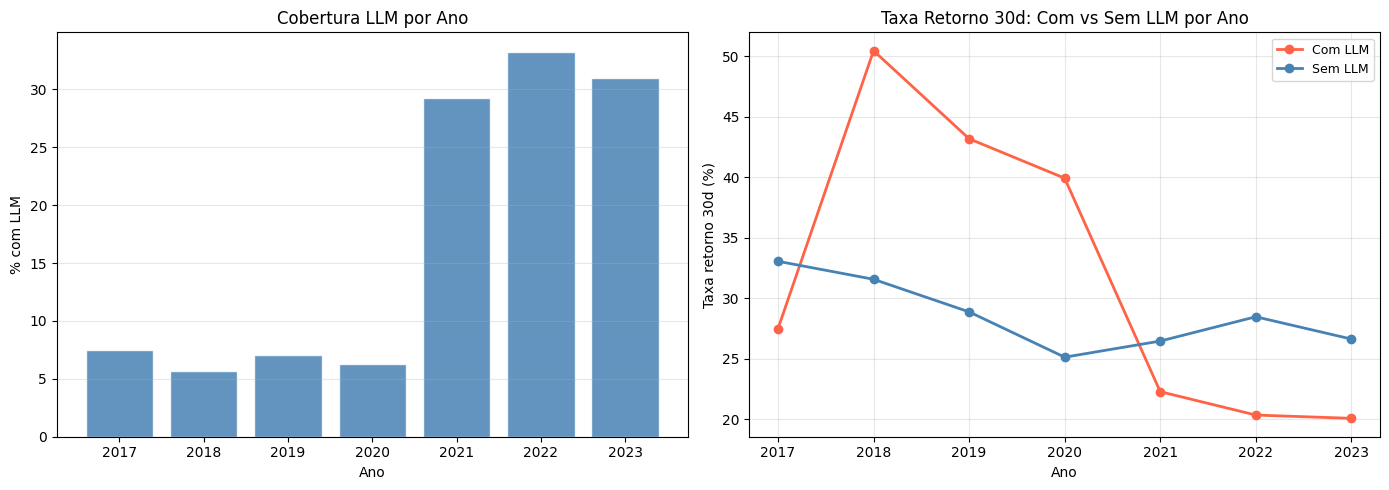

In [3]:
# Analisa se o subconjunto com LLM é representativo da população total
n_total   = len(df)
n_com_llm = int(df["tem_llm"].sum())
n_sem_llm = n_total - n_com_llm
print(f"\nCobertura LLM: {n_com_llm:,} ({n_com_llm/n_total*100:.1f}%) com LLM | "
      f"{n_sem_llm:,} ({n_sem_llm/n_total*100:.1f}%) sem LLM")

# Testa viés de seleção: distribuição do target entre com/sem LLM
for c in ["dt_atendimento"]:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors="coerce")
df["ano"] = df["dt_atendimento"].dt.year
df["mes"] = df["dt_atendimento"].dt.month
df["y_retorno_30d"] = (df["sn_retorno_30d"].fillna("N")=="S").astype(int)
df["y_retorno_90d"] = (df["sn_retorno_90d"].fillna("N")=="S").astype(int)
df["y_obito"]       = (df["sn_obito"].fillna("N")=="S").astype(int)
df["y_desfecho"]    = ((df["y_obito"]==1) |
                       (pd.to_numeric(df["qtd_obito_neonatal"],errors="coerce").fillna(0)>0)).astype(int)

# Viés: comparação entre subpopulações
print("\nAnálise de viés de seleção LLM:")
bias_rows = []
for var in ["y_retorno_30d","y_retorno_90d","y_obito","idade_anos"]:
    if var not in df.columns: continue
    com = df[df["tem_llm"]==1][var].dropna()
    sem = df[df["tem_llm"]==0][var].dropna()
    try:
        _, p = scipy_stats.mannwhitneyu(com, sem, alternative="two-sided")
    except Exception:
        p = np.nan
    print(f"  {var:<25}: com_LLM={com.mean():.3f}  sem_LLM={sem.mean():.3f}  "
          f"Δ={com.mean()-sem.mean():+.3f}  p={p:.4f}")
    bias_rows.append({"variavel": var, "com_llm": round(com.mean(),4),
                      "sem_llm": round(sem.mean(),4),
                      "delta": round(com.mean()-sem.mean(),4), "p_mw": round(p,5)})

pd.DataFrame(bias_rows).to_csv(OUT_DIR/"vies_selecao_llm.csv", index=False)

# Cobertura LLM por ano
cob_ano = df.groupby("ano")["tem_llm"].agg(["sum","count","mean"]).reset_index()
cob_ano.columns = ["ano","n_llm","n_total","pct_llm"]
cob_ano["pct_llm"] *= 100
print("\nCobertura LLM por ano:")
print(cob_ano.to_string(index=False))
cob_ano.to_csv(OUT_DIR/"cobertura_llm_por_ano.csv", index=False)

fig_cov, axes_cov = plt.subplots(1, 2, figsize=(14, 5))
axes_cov[0].bar(cob_ano["ano"], cob_ano["pct_llm"], color="steelblue", edgecolor="white", alpha=0.85)
axes_cov[0].set_xlabel(T["cob_xlabel"]); axes_cov[0].set_ylabel(T["cob_ylabel"])
axes_cov[0].set_title(T["cob_title"]); axes_cov[0].grid(axis="y", alpha=0.3)

ret_by_llm = df.groupby(["ano","tem_llm"])["y_retorno_30d"].mean().reset_index()
for llm_val, lbl, cor in [(1,"Com LLM","tomato"), (0,"Sem LLM","steelblue")]:
    sub = ret_by_llm[ret_by_llm["tem_llm"]==llm_val]
    axes_cov[1].plot(sub["ano"], sub["y_retorno_30d"]*100, "o-", color=cor, lw=2, label=lbl)
axes_cov[1].set_xlabel(T["cob_xlabel"]); axes_cov[1].set_ylabel(T["cob_retorno_ylabel"])
axes_cov[1].set_title(T["cob_retorno_title"])
axes_cov[1].legend(fontsize=9); axes_cov[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_DIR/"00_cobertura_llm.png", dpi=150); plt.show(); plt.close()

## 3. EDA das Features LLM — Distribuição e Correlação com Desfecho

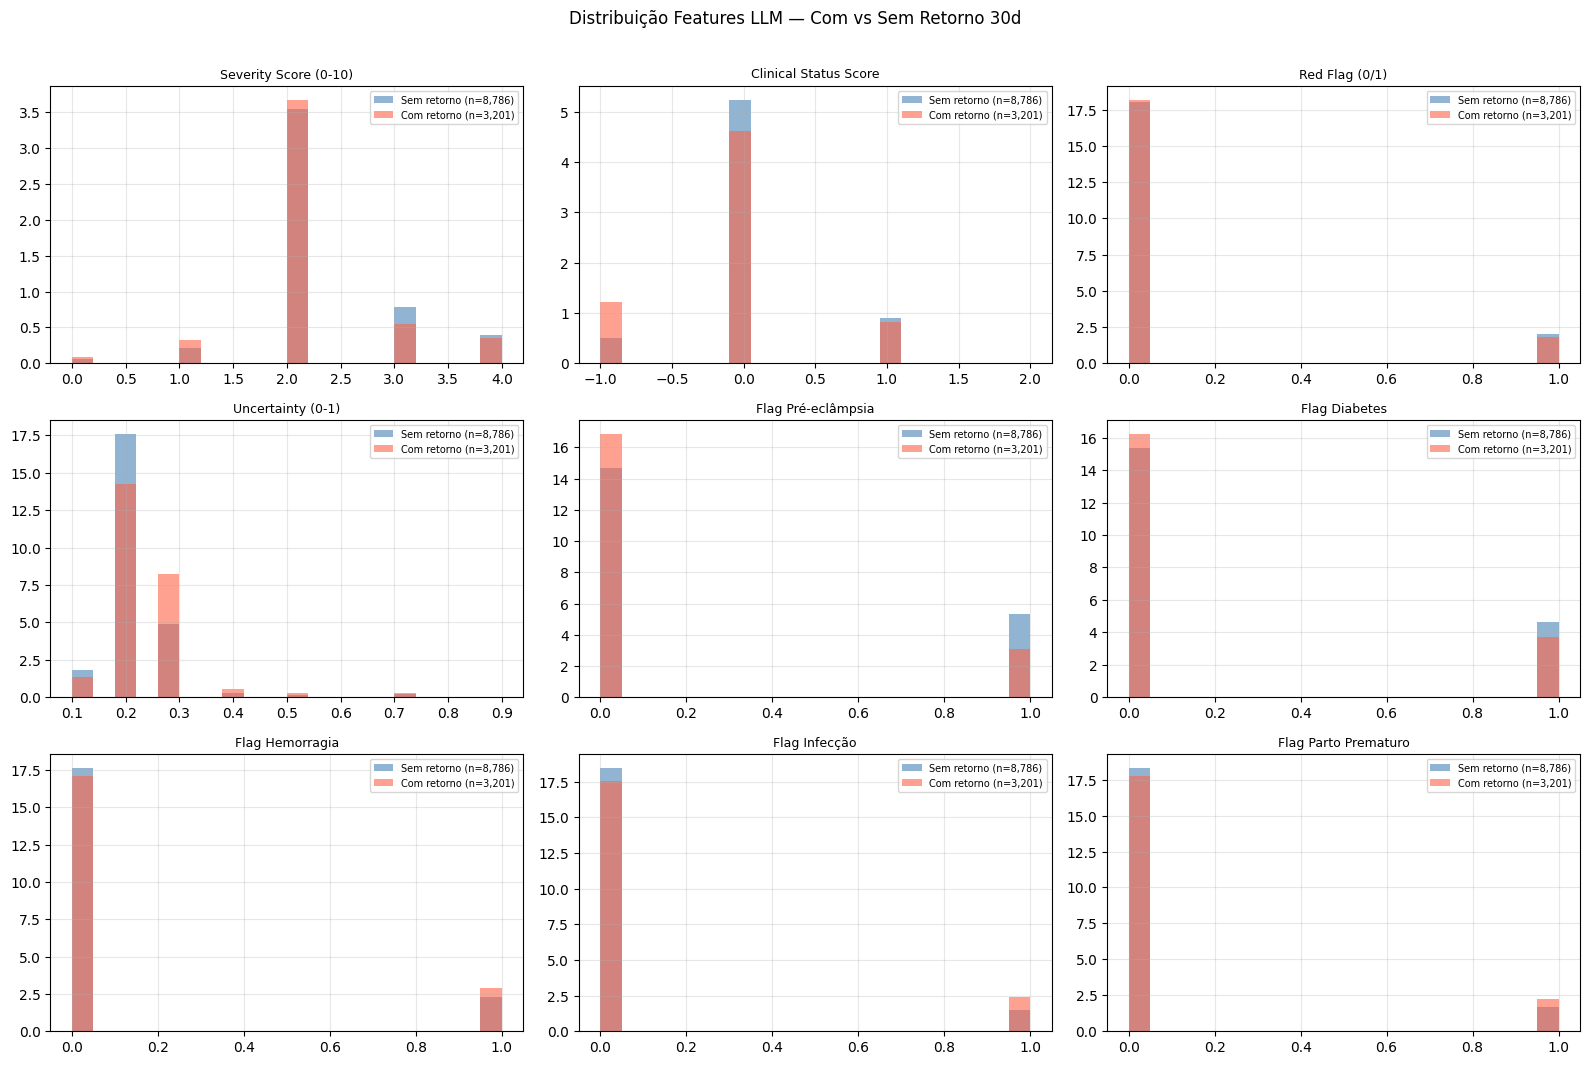

In [4]:
FEAT_LLM_NOMES = {
    "severity_score":       "Severity Score (0-10)",
    "clinical_status_score":"Clinical Status Score",
    "red_flag":             "Red Flag (0/1)",
    "uncertainty":          "Uncertainty (0-1)",
    "flag_pre_eclampsia":   "Flag Pré-eclâmpsia",
    "flag_diabetes":        "Flag Diabetes",
    "flag_hemorragia":      "Flag Hemorragia",
    "flag_infeccao":        "Flag Infecção",
    "flag_parto_prematuro": "Flag Parto Prematuro",
}
FEAT_LLM = list(FEAT_LLM_NOMES.keys())
df_llm = df[df["tem_llm"]==1].copy()

print(f"\nEDA features LLM (n={len(df_llm):,}):")
eda_llm = []
for col, lbl in FEAT_LLM_NOMES.items():
    if col not in df.columns: continue
    s = pd.to_numeric(df_llm[col], errors="coerce").dropna()
    fill = len(s) / len(df_llm) * 100
    corr_ret = df_llm[["y_retorno_30d", col]].dropna()
    try:
        r, p = scipy_stats.spearmanr(corr_ret["y_retorno_30d"], corr_ret[col])
    except Exception:
        r, p = np.nan, np.nan
    print(f"  {lbl:<30}: med={s.median():.2f}  fill={fill:.1f}%  "
          f"ρ(retorno)={r:.3f}  p={p:.4f}")
    eda_llm.append({"feature": col, "label": lbl, "mediana": round(s.median(),3),
                    "fill_pct": round(fill,1), "spearman_r": round(r,4),
                    "p_spearman": round(p,5)})

pd.DataFrame(eda_llm).to_csv(OUT_DIR/"eda_features_llm.csv", index=False)

# Plot distribuições LLM
feats_llm_presentes = [f for f in FEAT_LLM if f in df.columns]
ncols = 3
nrows = (len(feats_llm_presentes) + ncols - 1) // ncols
fig_llm, axes_llm = plt.subplots(nrows, ncols, figsize=(16, nrows * 3.5))
axes_llm = axes_llm.ravel() if nrows > 1 else [axes_llm] if ncols == 1 else axes_llm.ravel()
for i, col in enumerate(feats_llm_presentes):
    ax = axes_llm[i]
    s = pd.to_numeric(df_llm[col], errors="coerce").dropna()
    # Distribuição por retorno_30d
    s0 = pd.to_numeric(df_llm[df_llm["y_retorno_30d"]==0][col], errors="coerce").dropna()
    s1 = pd.to_numeric(df_llm[df_llm["y_retorno_30d"]==1][col], errors="coerce").dropna()
    ax.hist(s0, bins=20, alpha=0.6, color="steelblue", density=True, label=T["dist_lbl_sem_fmt"].format(n=len(s0)))
    ax.hist(s1, bins=20, alpha=0.6, color="tomato",    density=True, label=T["dist_lbl_com_fmt"].format(n=len(s1)))
    ax.set_title(FEAT_LLM_NOMES.get(col, col), fontsize=9)
    ax.legend(fontsize=7); ax.grid(alpha=0.3)
for j in range(len(feats_llm_presentes), len(axes_llm)):
    axes_llm[j].set_visible(False)
plt.suptitle(T["dist_title"], fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(PLOT_DIR/"01_dist_features_llm.png", dpi=150, bbox_inches="tight"); plt.show(); plt.close()

## 4. Preprocessamento — MICE + Split Temporal

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score,
                              brier_score_loss, roc_curve, precision_recall_curve)

try:
    from xgboost import XGBClassifier; HAS_XGB = True
except ImportError:
    HAS_XGB = False; print("XGBoost não instalado")

try:
    from lightgbm import LGBMClassifier; HAS_LGB = True
except ImportError:
    HAS_LGB = False

def seg_cid(c):
    if pd.isna(c): return "SEM_CID"
    c = str(c).upper()
    if c[:3] in [f"O{i:02d}" for i in range(10,17)]: return "HIPERTENSIVOS"
    if c[:3]=="O24":                                   return "DIABETES_GEST"
    if c[:3] in ["O60","O42","O47"]:                   return "PARTO_PREMATURO"
    if c[0]=="O" and c[1] in "234":                    return "HEMORRAGIA"
    if c[:3]=="O98":                                   return "INFECCAO"
    if c[:3]=="O99":                                   return "COMORBIDADES"
    if c[0]=="P":                                      return "RISCO_NEONATAL"
    if c[0]=="O":                                      return "OUTROS_OBST"
    return "OUTROS"

df["segmento_cid"] = df["cd_cid"].apply(seg_cid)

# Converte colunas numéricas
_num_cols = [
    "idade_anos","semanas_gestacao","G_obs","A_obs","C_obs","IG_obs","N_obs",
    "vl_escore_triagem","cd_cor_manchester","qtd_problemas","retorno_anterior",
    "sn_gestacao_tiss","sn_aborto_tiss","sn_complicacao_tiss","sn_cesario_tiss",
    "severity_score","clinical_status_score","red_flag","llm_ig_semanas",
    "uncertainty","flag_pre_eclampsia","flag_diabetes","flag_hemorragia",
    "flag_infeccao","flag_parto_prematuro",
    "primigesta","grande_multipara_v2","tem_aborto_v2","tem_cesarea_v2",
    "risco_gestacao","gestacao_gemelar","gestacao_pretermo",
    "aborto_recorrente","sem_filhos_vivos","perda_previa",
    "perdas_nao_explicadas","razao_perda",
]
for c in _num_cols:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

for c in ["sn_gestacao_tiss","sn_aborto_tiss","sn_complicacao_tiss","sn_cesario_tiss"]:
    if c in df.columns:
        df[c+"_bin"] = (df[c].fillna("N")=="S").astype(int)

TREINO_FIM = 2020
VALID_ANO  = 2021
TESTE_INI  = 2022

df_train = df[df["ano"] <= TREINO_FIM].copy()
df_valid = df[df["ano"] == VALID_ANO].copy()
df_test  = df[df["ano"] >= TESTE_INI].copy()

print(f"\nTreino (≤{TREINO_FIM}): {len(df_train):,}  "
      f"(LLM: {int(df_train['tem_llm'].sum()):,} = {df_train['tem_llm'].mean()*100:.1f}%)")
print(f"Valid  ( {VALID_ANO} ): {len(df_valid):,}  "
      f"(LLM: {int(df_valid['tem_llm'].sum()):,} = {df_valid['tem_llm'].mean()*100:.1f}%)")
print(f"Teste  (≥{TESTE_INI}): {len(df_test):,}  "
      f"(LLM: {int(df_test['tem_llm'].sum()):,} = {df_test['tem_llm'].mean()*100:.1f}%)")

def make_preprocessor(X):
    """MICE para numéricas, OHE para categóricas."""
    num = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    cat = [c for c in X.columns if c not in num]
    return ColumnTransformer([
        ("num", Pipeline([
            ("imp", IterativeImputer(max_iter=10, random_state=42, min_value=0)),
            ("sc",  StandardScaler()),
        ]), num),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), cat),
    ], remainder="drop")

## 5. Definição dos Conjuntos de Features — Ablação 3 níveis

In [6]:
# Anti-leakage: apenas features disponíveis na admissão
FEAT_ADMISSAO = [
    # Demográficas / administrativas
    "idade_anos", "tp_atendimento", "mes", "segmento_cid",
    # Triagem
    "vl_escore_triagem", "cd_cor_manchester",
    # Flags TISS
    "sn_gestacao_tiss_bin", "sn_aborto_tiss_bin",
    "sn_complicacao_tiss_bin", "sn_cesario_tiss_bin",
    # Comorbidades / histórico
    "qtd_problemas", "retorno_anterior",
]

FEAT_OBSTETRICA = [
    # Via texto (regex + LLM)
    "G_obs", "A_obs", "C_obs", "IG_obs", "N_obs",
    "tipo_gestacao", "perfil_historico",
    "primigesta", "grande_multipara_v2",
    "tem_aborto_v2", "tem_cesarea_v2",
    "risco_gestacao", "gestacao_gemelar", "gestacao_pretermo",
    "aborto_recorrente", "sem_filhos_vivos", "perda_previa",
    "perdas_nao_explicadas", "razao_perda",
    # Estruturado (fallback)
    "semanas_gestacao",
]

FEAT_LLM_MODEL = [
    "severity_score", "clinical_status_score", "red_flag",
    "llm_ig_semanas", "uncertainty",
    "flag_pre_eclampsia", "flag_diabetes", "flag_hemorragia",
    "flag_infeccao", "flag_parto_prematuro",
    "tem_llm",  # flag de cobertura — modelo aprende quando LLM está disponível
]

FEAT_M3 = [f for f in FEAT_ADMISSAO                                   if f in df.columns]
FEAT_M4 = [f for f in FEAT_ADMISSAO + FEAT_OBSTETRICA                 if f in df.columns]
FEAT_M5 = [f for f in FEAT_ADMISSAO + FEAT_OBSTETRICA + FEAT_LLM_MODEL if f in df.columns]

print(f"\nM3 — admissão (anti-leakage):            {len(FEAT_M3)} features")
print(f"M4 — M3 + obstétricas enriquecidas:      {len(FEAT_M4)} features")
print(f"M5 — M4 + LLM (LEFT JOIN, tem_llm flag): {len(FEAT_M5)} features")
print(f"\nFeatures LLM no M5 presentes: "
      f"{[f for f in FEAT_LLM_MODEL if f in df.columns]}")

## 6. Treinamento dos Modelos de Ablação

In [7]:
def avaliar(y_true, y_prob, n_boot=500):
    """AUROC, AUPRC, Brier com IC95% bootstrap."""
    y_true, y_prob = np.array(y_true), np.array(y_prob)
    if y_true.sum() == 0: return {}
    base = dict(
        auroc=roc_auc_score(y_true, y_prob),
        auprc=average_precision_score(y_true, y_prob),
        brier=brier_score_loss(y_true, y_prob),
    )
    boots = []
    rng = np.random.default_rng(42)
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        yt, yp = y_true[idx], y_prob[idx]
        if yt.sum()==0 or yt.sum()==len(yt): continue
        boots.append(dict(auroc=roc_auc_score(yt,yp),
                          auprc=average_precision_score(yt,yp),
                          brier=brier_score_loss(yt,yp)))
    out = {}
    for k, v in base.items():
        lo = np.percentile([b[k] for b in boots], 2.5)  if boots else np.nan
        hi = np.percentile([b[k] for b in boots], 97.5) if boots else np.nan
        out[k]=round(v,4); out[f"{k}_lo"]=round(lo,4); out[f"{k}_hi"]=round(hi,4)
    return out

def delong_test(y_true, pa, pb):
    """DeLong 1988 — p-valor bilateral para diferença de AUROC."""
    def _wc(y, p):
        pos = p[y==1]; neg = p[y==0]
        n1, n0 = len(pos), len(neg)
        V10 = np.array([np.mean(pi > neg) + 0.5*np.mean(pi==neg) for pi in pos])
        V01 = np.array([np.mean(pi < pos) + 0.5*np.mean(pi==pos) for pi in neg])
        return V10, V01, n1, n0
    V10a,V01a,n1,n0 = _wc(y_true,pa); V10b,V01b,_,_ = _wc(y_true,pb)
    S10=np.cov(V10a,V10b); S01=np.cov(V01a,V01b)
    vd = S10[0,0]/n1+S01[0,0]/n0 + S10[1,1]/n1+S01[1,1]/n0 - 2*(S10[0,1]/n1+S01[0,1]/n0)
    if vd<=0: return 0.0, 1.0
    z=(V10a.mean()-V10b.mean())/np.sqrt(vd)
    return float(z), float(2*(1-scipy_stats.norm.cdf(abs(z))))

def nri_idi(y_true, p_ref, p_new):
    """NRI contínuo e IDI."""
    ev  = y_true==1; nev = y_true==0
    nri = (np.mean(np.sign(p_new[ev]-p_ref[ev])) +
           np.mean(np.sign(p_ref[nev]-p_new[nev])))
    idi = ((p_new[ev].mean()-p_new[nev].mean()) -
           (p_ref[ev].mean()-p_ref[nev].mean()))
    return {"nri": round(nri,4), "idi": round(idi,4)}

TARGET  = "y_retorno_30d"
y_train = df_train[TARGET].values
y_valid = df_valid[TARGET].values
y_test  = df_test[TARGET].values

_xgb_params = dict(n_estimators=400, max_depth=5, learning_rate=0.05,
                   subsample=0.8, colsample_bytree=0.8,
                   eval_metric="auc", n_jobs=-1, random_state=42, verbosity=0)

configs = {}
if HAS_XGB:
    configs["M3_XGB"] = (FEAT_M3, XGBClassifier(**_xgb_params))
    configs["M4_XGB"] = (FEAT_M4, XGBClassifier(**_xgb_params))
    configs["M5_XGB"] = (FEAT_M5, XGBClassifier(**_xgb_params))
if HAS_LGB:
    configs["M5_LGB"] = (FEAT_M5,
        LGBMClassifier(n_estimators=400, max_depth=5, learning_rate=0.05,
                       n_jobs=-1, random_state=42, verbose=-1))

resultados  = []
modelos_fit = {}
probs_teste = {}

for nome, (feats, clf) in configs.items():
    print(f"\n[{nome}] {len(feats)} features...", end=" ", flush=True)
    X_tr = df_train[feats]; X_va = df_valid[feats]; X_te = df_test[feats]
    pre = make_preprocessor(X_tr)
    X_tr_t = pre.fit_transform(X_tr)
    X_va_t = pre.transform(X_va)
    X_te_t = pre.transform(X_te)
    clf.fit(X_tr_t, y_train)
    modelos_fit[nome] = (clf, pre, feats)
    prob_va = clf.predict_proba(X_va_t)[:,1]
    prob_te = clf.predict_proba(X_te_t)[:,1]
    probs_teste[nome] = prob_te
    m_va = avaliar(y_valid, prob_va)
    m_te = avaliar(y_test,  prob_te)
    print(f"AUROC valid={m_va.get('auroc','?'):.4f}  teste={m_te.get('auroc','?'):.4f}")
    resultados.append({"modelo": nome, "n_features": len(feats),
                       **{f"va_{k}":v for k,v in m_va.items()},
                       **{f"te_{k}":v for k,v in m_te.items()}})

# Análise INNER JOIN (sensibilidade): avalia apenas no subconjunto com LLM
mask_llm_test = (df_test["tem_llm"]==1).values
y_test_llm    = y_test[mask_llm_test]
print(f"\n[Sensibilidade] Avaliação INNER JOIN: n_test_llm={mask_llm_test.sum():,}")
for nome in probs_teste:
    prob_llm = probs_teste[nome][mask_llm_test]
    m_llm = avaliar(y_test_llm, prob_llm, n_boot=300)
    r = next(r for r in resultados if r["modelo"]==nome)
    r.update({f"inner_{k}":v for k,v in m_llm.items()})
    print(f"  [{nome}] AUROC (inner_join)={m_llm.get('auroc','?'):.4f}")

## 7. Tabela de Ablação Completa

In [8]:
rows_ab = []
for r in resultados:
    def _fmt(prefix, k):
        v = r.get(f"{prefix}{k}", np.nan)
        lo = r.get(f"{prefix}{k}_lo", np.nan)
        hi = r.get(f"{prefix}{k}_hi", np.nan)
        try:
            return f"{v:.4f} [{lo:.4f}–{hi:.4f}]"
        except Exception:
            return "—"

    rows_ab.append({
        "Modelo":         r["modelo"],
        "N features":     r["n_features"],
        "AUROC (full)":   _fmt("te_","auroc"),
        "AUPRC (full)":   _fmt("te_","auprc"),
        "Brier (full)":   f"{r.get('te_brier',np.nan):.4f}",
        "AUROC (inner)":  _fmt("inner_","auroc"),
    })

tab_ab = pd.DataFrame(rows_ab)
print("\nTabela de Ablação — Conjunto de Teste:")
print(tab_ab.to_string(index=False))
tab_ab.to_csv(OUT_DIR/"tabela_ablacao.csv", index=False)

# Delta AUROC
print("\nDelta AUROC (ganho por nível de ablação):")
for ref_nome, cmp_nome, lbl in [
    ("M3_XGB","M4_XGB","M4 vs M3 (+obstétricas)"),
    ("M3_XGB","M5_XGB","M5 vs M3 (+obstétricas +LLM)"),
    ("M4_XGB","M5_XGB","M5 vs M4 (+LLM apenas)"),
]:
    if ref_nome in probs_teste and cmp_nome in probs_teste:
        a_ref = roc_auc_score(y_test, probs_teste[ref_nome])
        a_cmp = roc_auc_score(y_test, probs_teste[cmp_nome])
        print(f"  {lbl}: {a_ref:.4f} → {a_cmp:.4f}  Δ={a_cmp-a_ref:+.4f}")

## 8. Testes Estatísticos — DeLong + NRI/IDI

In [9]:
print("\n" + "="*70)
print("TESTES ESTATÍSTICOS — ABLAÇÃO")
print("="*70)

modelos_list = list(probs_teste.keys())
rows_stat = []

# DeLong: todos vs M3 (referência)
ref_nome = "M3_XGB" if "M3_XGB" in probs_teste else modelos_list[0]
n_comp = len(modelos_list) - 1
alpha_bonf = 0.05 / max(n_comp, 1)
print(f"\nTeste DeLong vs {ref_nome} (α Bonferroni={alpha_bonf:.4f}):")
print(f"{'Modelo':<15} {'AUROC':>8} {'Δ AUROC':>8} {'Z':>7} {'p-valor':>9} {'Sig':>5}")
print("-"*55)

for nome in probs_teste:
    if nome == ref_nome: continue
    z, p = delong_test(y_test, probs_teste[nome], probs_teste[ref_nome])
    a_n  = roc_auc_score(y_test, probs_teste[nome])
    a_r  = roc_auc_score(y_test, probs_teste[ref_nome])
    sig  = "***" if p < alpha_bonf else "* " if p < 0.05 else "ns"
    print(f"  {nome:<13} {a_n:>8.4f} {a_n-a_r:>+8.4f} {z:>7.3f} {p:>9.4f} {sig:>5}")
    rows_stat.append({"comparacao": f"{nome} vs {ref_nome}", "auroc_novo": round(a_n,4),
                      "delta_auroc": round(a_n-a_r,4), "z": round(z,3),
                      "p_delong": round(p,5), "sig_bonf": p < alpha_bonf})

pd.DataFrame(rows_stat).to_csv(OUT_DIR/"testes_delong_ablacao.csv", index=False)

# NRI/IDI
print(f"\nNRI / IDI vs {ref_nome}:")
rows_nri = []
for nome in probs_teste:
    if nome == ref_nome: continue
    res = nri_idi(y_test, probs_teste[ref_nome], probs_teste[nome])
    print(f"  {nome:<15} NRI={res['nri']:>+7.4f}  IDI={res['idi']:>+7.4f}")
    rows_nri.append({"modelo": nome, "ref": ref_nome, **res})

pd.DataFrame(rows_nri).to_csv(OUT_DIR/"nri_idi_ablacao.csv", index=False)

## 9. Curvas ROC e PR — Comparação de Ablação

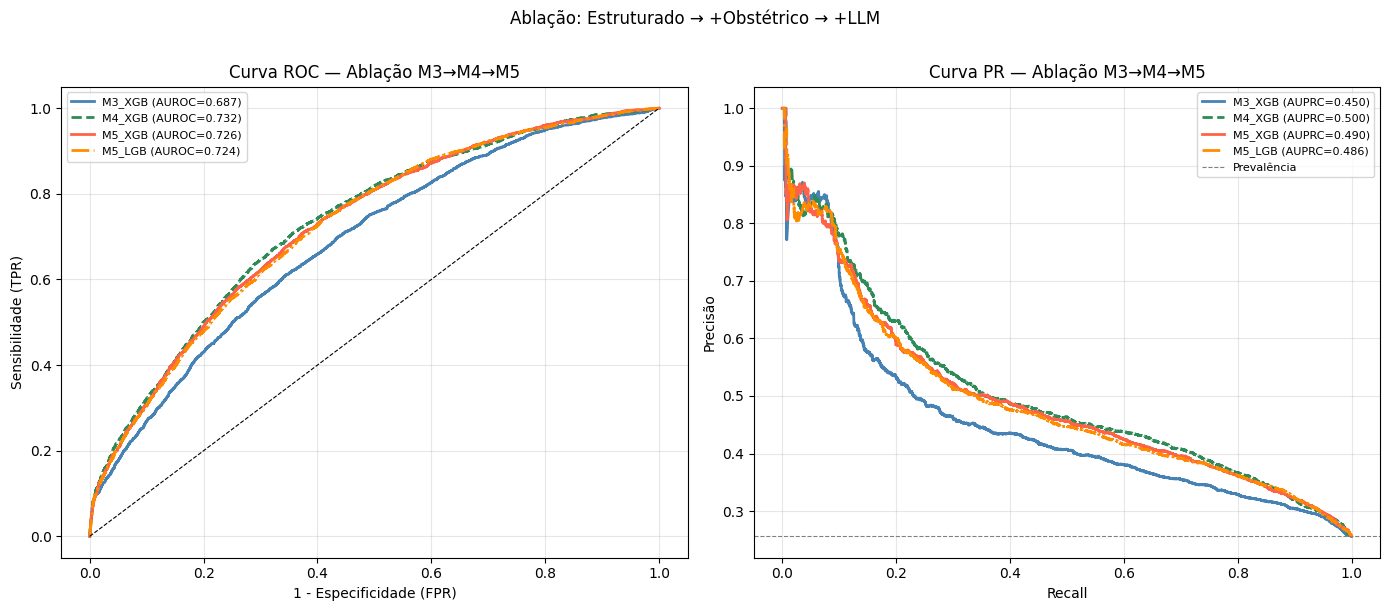

In [10]:
CORES_AB = {"M3_XGB":"steelblue","M4_XGB":"seagreen","M5_XGB":"tomato","M5_LGB":"darkorange"}
LS_AB    = {"M3_XGB":"-","M4_XGB":"--","M5_XGB":"-","M5_LGB":"-."}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for nome, (clf, pre, feats) in modelos_fit.items():
    X_te_t = pre.transform(df_test[feats])
    prob   = clf.predict_proba(X_te_t)[:,1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    axes[0].plot(fpr, tpr, color=CORES_AB.get(nome,"gray"),
                 ls=LS_AB.get(nome,"-"), lw=2, label=f"{nome} (AUROC={auc:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    axes[1].plot(rec, prec, color=CORES_AB.get(nome,"gray"),
                 ls=LS_AB.get(nome,"-"), lw=2, label=f"{nome} (AUPRC={ap:.3f})")

axes[0].plot([0,1],[0,1],"k--",lw=0.8)
axes[0].set_title(T["roc_title"])
axes[0].set_xlabel(T["roc_xlabel"]); axes[0].set_ylabel(T["roc_ylabel"])
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].axhline(y_test.mean(), color="gray", ls="--", lw=0.8, label=T["pr_prev_lbl"])
axes[1].set_title(T["pr_title"])
axes[1].set_xlabel(T["pr_xlabel"]); axes[1].set_ylabel(T["pr_ylabel"])
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.suptitle(T["abl_suptitle"], fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(PLOT_DIR/"02_roc_pr_ablacao.png", dpi=150, bbox_inches="tight"); plt.show(); plt.close()

## 10. SHAP — Contribuição Diferencial do LLM

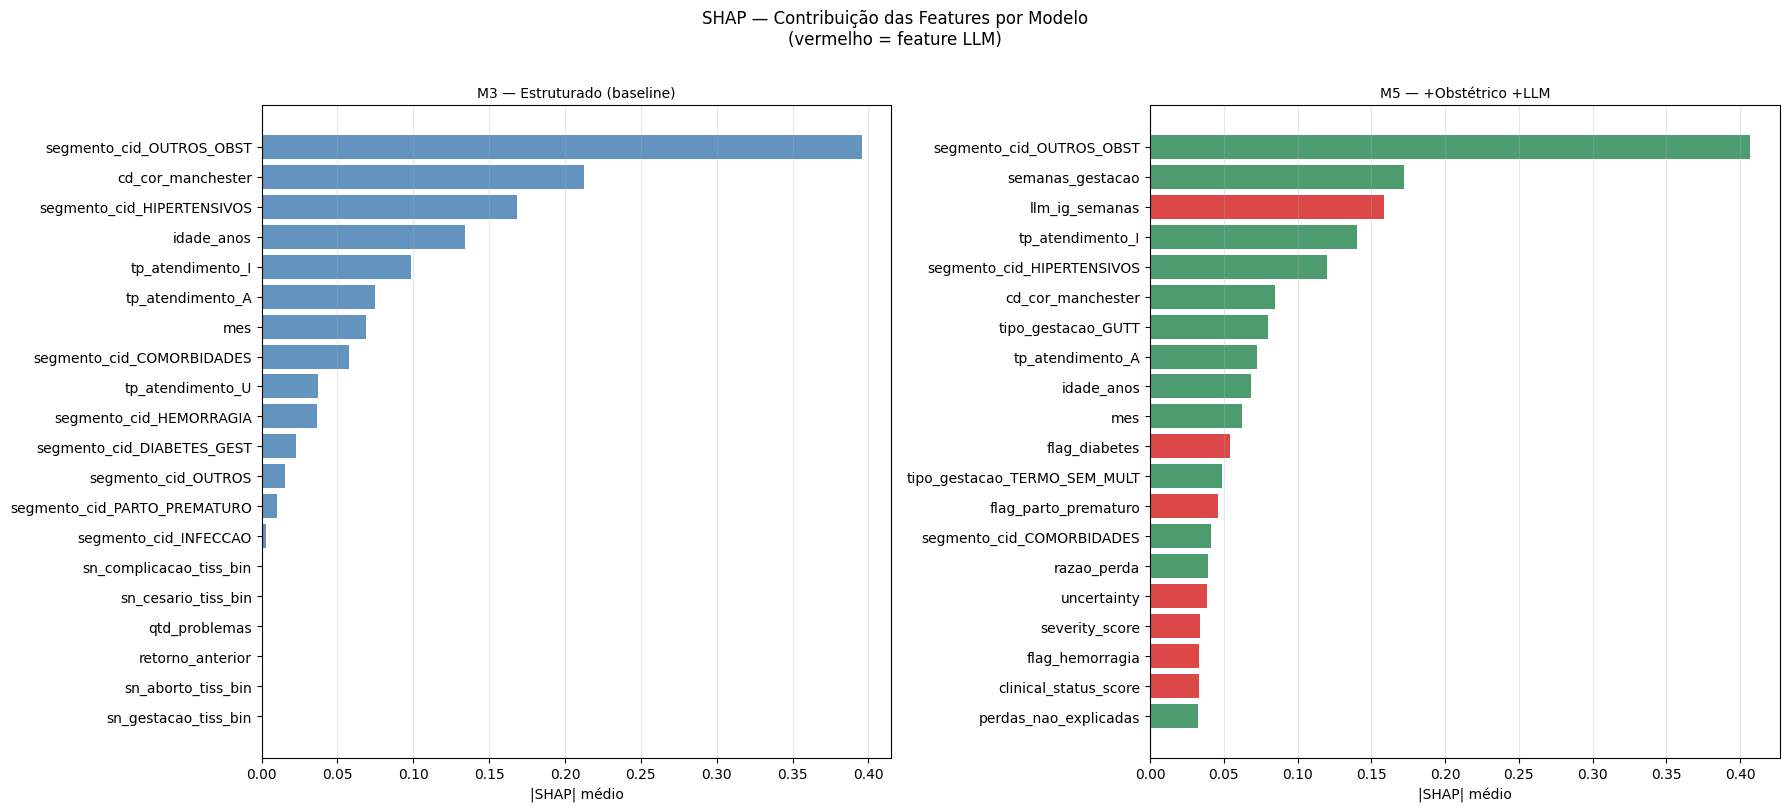

In [11]:
try:
    import shap

    fig_shap, axes_shap = plt.subplots(1, 2, figsize=(18, 8))

    shap_importancias = {}

    for nome, ax, titulo in [
        ("M3_XGB", axes_shap[0], "M3 — Estruturado (baseline)"),
        ("M5_XGB", axes_shap[1], "M5 — +Obstétrico +LLM"),
    ]:
        if nome not in modelos_fit: continue
        clf_s, pre_s, feats_s = modelos_fit[nome]
        feat_names = [n.split("__",1)[-1] for n in pre_s.get_feature_names_out()]
        X_te_t_s = pre_s.transform(df_test[feats_s])
        rng = np.random.default_rng(42)
        idx_s = rng.integers(0, len(X_te_t_s), min(800, len(X_te_t_s)))
        X_s = np.asarray(X_te_t_s[idx_s])

        exp = shap.TreeExplainer(clf_s)
        sv = exp.shap_values(X_s)
        if isinstance(sv, list): sv = sv[1]
        if getattr(sv,"ndim",0)==3: sv = sv[:,:,1]
        sv = np.asarray(sv)

        sm = np.abs(sv).mean(axis=0)
        sdf = pd.DataFrame({"feature": feat_names, "shap": sm}) \
                .sort_values("shap", ascending=False).head(20)

        # Colore features LLM em vermelho
        is_llm = sdf["feature"].isin(FEAT_LLM_MODEL)
        cores_s = ["#d62728" if l else ("seagreen" if nome=="M5_XGB" else "steelblue")
                   for l in is_llm]

        ax.barh(sdf["feature"][::-1], sdf["shap"][::-1], color=cores_s[::-1], alpha=0.85)
        ax.set_xlabel(T["shap_xlabel"]); ax.set_title(titulo, fontsize=10)
        ax.grid(axis="x", alpha=0.3)

        shap_importancias[nome] = sdf
        sdf["modelo"] = nome
        sdf["is_llm"] = is_llm.values

    plt.suptitle(T["shap_suptitle"], fontsize=12, y=1.01)
    plt.tight_layout()
    plt.savefig(PLOT_DIR/"03_shap_ablacao_m3_vs_m5.png", dpi=150, bbox_inches="tight")
    plt.show(); plt.close()

    # SHAP: ranking LLM features no M5
    if "M5_XGB" in shap_importancias:
        sdf_m5 = shap_importancias["M5_XGB"]
        llm_rank = sdf_m5[sdf_m5["is_llm"]].reset_index(drop=True)
        print("\nRanking SHAP — Features LLM no M5:")
        print(llm_rank[["feature","shap"]].to_string(index=False))
        llm_rank.to_csv(OUT_DIR/"shap_features_llm_ranking.csv", index=False)

    # Salva importâncias
    pd.concat(shap_importancias.values(), ignore_index=True).to_csv(
        OUT_DIR/"shap_importancias_ablacao.csv", index=False)

except ImportError:
    print("SHAP não instalado: pip install shap")
except Exception as e:
    print(f"Erro SHAP: {e}")
    import traceback; traceback.print_exc()

## 11. Análise por Subgrupo CID — O LLM ajuda mais em quais segmentos?

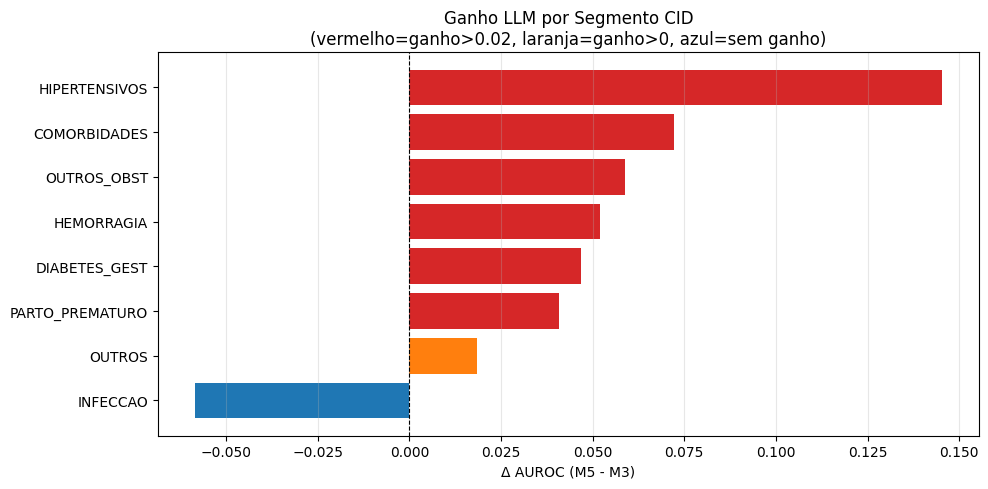

In [12]:
print("\n" + "="*70)
print("GANHO LLM POR SUBGRUPO CID")
print("="*70)

if "M3_XGB" in modelos_fit and "M5_XGB" in modelos_fit:
    df_test_eval = df_test.copy()
    df_test_eval["prob_m3"] = probs_teste["M3_XGB"]
    df_test_eval["prob_m5"] = probs_teste["M5_XGB"]

    rows_seg = []
    for seg in df_test_eval["segmento_cid"].dropna().unique():
        mask = df_test_eval["segmento_cid"] == seg
        sub  = df_test_eval[mask]
        n    = len(sub); n_pos = int(sub[TARGET].sum())
        if n_pos < 10: continue
        try:
            auroc_m3 = roc_auc_score(sub[TARGET], sub["prob_m3"])
            auroc_m5 = roc_auc_score(sub[TARGET], sub["prob_m5"])
            z, p     = delong_test(sub[TARGET].values, sub["prob_m5"].values, sub["prob_m3"].values)
            n_llm_s  = int(sub["tem_llm"].sum())
        except Exception:
            continue
        rows_seg.append({
            "segmento_cid": seg, "n": n, "n_pos": n_pos,
            "n_llm": n_llm_s, "pct_llm": round(n_llm_s/n*100,1),
            "auroc_m3": round(auroc_m3,4), "auroc_m5": round(auroc_m5,4),
            "delta_auroc": round(auroc_m5-auroc_m3,4),
            "p_delong": round(p,5),
        })
        print(f"  {seg:<20}: M3={auroc_m3:.4f}  M5={auroc_m5:.4f}  "
              f"Δ={auroc_m5-auroc_m3:+.4f}  LLM={n_llm_s}/{n} ({n_llm_s/n*100:.0f}%)")

    tab_seg = pd.DataFrame(rows_seg).sort_values("delta_auroc", ascending=False)
    tab_seg.to_csv(OUT_DIR/"ganho_llm_por_segmento.csv", index=False)

    if len(tab_seg) > 0:
        fig_seg, ax_seg = plt.subplots(figsize=(10, 5))
        cores_seg = ["#d62728" if d > 0.02 else "#ff7f0e" if d > 0
                     else "#1f77b4" for d in tab_seg["delta_auroc"]]
        ax_seg.barh(tab_seg["segmento_cid"][::-1],
                    tab_seg["delta_auroc"][::-1], color=cores_seg[::-1])
        ax_seg.axvline(0, color="black", lw=0.8, ls="--")
        ax_seg.set_xlabel(T["ganho_ylabel"])
        ax_seg.set_title(T["ganho_title_fmt"].format(
            extra="(vermelho=ganho>0.02, laranja=ganho>0, azul=sem ganho)"))
        ax_seg.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.savefig(PLOT_DIR/"04_ganho_llm_por_segmento.png", dpi=150); plt.show(); plt.close()
        print("  Gerado: plots/04_ganho_llm_por_segmento.png")

## 12. Análise de Casos Alterados pelo LLM

Identifica pacientes onde a inclusão de features LLM muda substancialmente
a predição — revelando onde o texto clínico acrescenta mais informação.

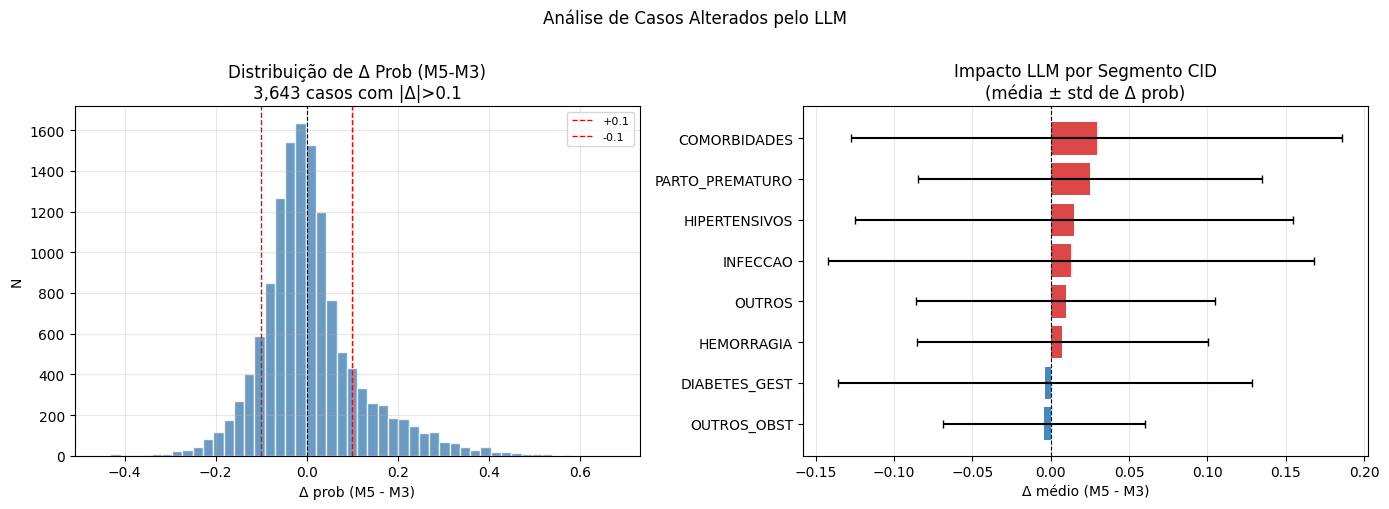

In [13]:
if "M3_XGB" in probs_teste and "M5_XGB" in probs_teste:
    df_diff = df_test[["cd_atendimento","cd_paciente","segmento_cid",
                        TARGET,"tem_llm","severity_score","red_flag"]].copy()
    df_diff["prob_m3"] = probs_teste["M3_XGB"]
    df_diff["prob_m5"] = probs_teste["M5_XGB"]
    df_diff["delta"]   = df_diff["prob_m5"] - df_diff["prob_m3"]
    df_diff["abs_delta"] = df_diff["delta"].abs()

    # Casos onde LLM muda decisão (|Δ| > 0.10)
    thr_delta = 0.10
    n_alterados = (df_diff["abs_delta"] > thr_delta).sum()
    print(f"\nCasos com |Δ prob| > {thr_delta}: {n_alterados:,} "
          f"({n_alterados/len(df_diff)*100:.1f}% do teste)")

    # Quem tem LLM vs quem não tem
    df_c_llm = df_diff[df_diff["tem_llm"]==1]
    df_s_llm = df_diff[df_diff["tem_llm"]==0]
    print(f"  Δ médio (com LLM): {df_c_llm['delta'].mean():+.4f}  "
          f"std={df_c_llm['delta'].std():.4f}")
    print(f"  Δ médio (sem LLM): {df_s_llm['delta'].mean():+.4f}  "
          f"std={df_s_llm['delta'].std():.4f}")

    # Plot distribuição de Δ
    fig_diff, axes_diff = plt.subplots(1, 2, figsize=(14, 5))
    axes_diff[0].hist(df_diff["delta"], bins=50, color="steelblue", edgecolor="white", alpha=0.8)
    axes_diff[0].axvline(0, color="black", lw=0.8, ls="--")
    axes_diff[0].axvline( thr_delta, color="red",  lw=1, ls="--", label=f"+{thr_delta}")
    axes_diff[0].axvline(-thr_delta, color="red",  lw=1, ls="--", label=f"-{thr_delta}")
    axes_diff[0].set_xlabel(T["delta_xlabel"]); axes_diff[0].set_ylabel(T["delta_ylabel"])
    axes_diff[0].set_title(T["delta_title_fmt"].format(
        extra=f"{n_alterados:,} casos com |Δ|>{thr_delta}"))
    axes_diff[0].legend(fontsize=8); axes_diff[0].grid(alpha=0.3)

    # Δ por segmento CID
    delta_seg = df_diff.groupby("segmento_cid")["delta"].agg(["mean","std"]).reset_index()
    delta_seg = delta_seg.sort_values("mean", ascending=False)
    cores_ds = ["#d62728" if m>0 else "#1f77b4" for m in delta_seg["mean"]]
    axes_diff[1].barh(delta_seg["segmento_cid"][::-1], delta_seg["mean"][::-1],
                      xerr=delta_seg["std"][::-1], color=cores_ds[::-1],
                      capsize=3, alpha=0.85)
    axes_diff[1].axvline(0, color="black", lw=0.8, ls="--")
    axes_diff[1].set_xlabel(T["impacto_xlabel"])
    axes_diff[1].set_title(T["impacto_title"])
    axes_diff[1].grid(axis="x", alpha=0.3)
    plt.suptitle(T["casos_suptitle"], fontsize=12, y=1.01)
    plt.tight_layout()
    plt.savefig(PLOT_DIR/"05_casos_alterados_llm.png", dpi=150, bbox_inches="tight")
    plt.show(); plt.close()

    df_diff.sort_values("abs_delta", ascending=False).head(100).to_csv(
        OUT_DIR/"casos_mais_alterados_llm.csv", index=False)
    print("  Gerado: casos_mais_alterados_llm.csv")

In [14]:
print(f"""
╔══════════════════════════════════════════════════════════════╗
║  04 — Modelos com LLM — CONCLUÍDO                            ║
╠══════════════════════════════════════════════════════════════╣
║  Ablação: M3 (struct) → M4 (+obstétrico) → M5 (+LLM)        ║
║  LEFT JOIN (78k) + análise sensibilidade INNER JOIN (17k)    ║
╠══════════════════════════════════════════════════════════════╣
║  CSVs:                                                       ║
║   tabela_ablacao.csv          (AUROC full + inner)           ║
║   testes_delong_ablacao.csv   (DeLong + Bonferroni)          ║
║   nri_idi_ablacao.csv         (NRI/IDI vs M3)                ║
║   eda_features_llm.csv        (distribuição + correlação)    ║
║   vies_selecao_llm.csv        (teste de representatividade)  ║
║   cobertura_llm_por_ano.csv                                  ║
║   ganho_llm_por_segmento.csv  (Δ AUROC por CID)             ║
║   casos_mais_alterados_llm.csv (top-100 Δ > 0.10)           ║
║   shap_importancias_ablacao.csv                              ║
║   shap_features_llm_ranking.csv                              ║
╠══════════════════════════════════════════════════════════════╣
║  Plots:                                                      ║
║   00  Cobertura LLM por ano + viés                           ║
║   01  Distribuições features LLM (com vs sem retorno)        ║
║   02  ROC + PR — Ablação M3→M4→M5                           ║
║   03  SHAP comparativo M3 vs M5                              ║
║   04  Ganho LLM por segmento CID                             ║
║   05  Distribuição Δ prob (casos alterados)                  ║
╚══════════════════════════════════════════════════════════════╝
""")